## Milk Quality Prediction

### Setup

In [191]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, accuracy_score, roc_auc_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.feature_extraction import DictVectorizer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


### Data Preparation

In [192]:
# Load dataset
df_raw = pd.read_csv("../data/milknew.csv")
df = df_raw.copy()

# clean column names
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.rename(columns={"temprature": "temperature"}, inplace=True)
df.rename(columns={"fat_": "fat"}, inplace=True)

# Grade column values mapping
grade_mapping = {"low": 0, "medium": 0, "high": 1}
df["grade"] = df["grade"].map(grade_mapping)

df.head()

,ph,temperature,taste,odor,fat,turbidity,colour,grade
0,6.6,35,1,0,1,0,254,1
1,6.6,36,0,1,0,1,253,1
2,8.5,70,1,1,1,1,246,0
3,9.5,34,1,1,0,1,255,0
4,6.6,37,0,0,0,0,255,0


In [193]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1059 entries, 0 to 1058
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ph           1059 non-null   float64
 1   temperature  1059 non-null   int64  
 2   taste        1059 non-null   int64  
 3   odor         1059 non-null   int64  
 4   fat          1059 non-null   int64  
 5   turbidity    1059 non-null   int64  
 6   colour       1059 non-null   int64  
 7   grade        1059 non-null   int64  
dtypes: float64(1), int64(7)
memory usage: 66.3 KB


In [194]:
# Check missing values
df.isnull().sum()

ph             0
temperature    0
taste          0
odor           0
fat            0
turbidity      0
colour         0
grade          0
dtype: int64

In [195]:
# Validation framework
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['grade'].values
y_val = df_val['grade'].values
y_test = df_test['grade'].values

del df_train['grade']
del df_val['grade']
del df_test['grade']


### EDA

#### Unique data

In [196]:

for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print('-----')


ph
[6.6 8.5 9.5 5.5 4.5]
16
-----
temperature
[35 36 70 34 37]
17
-----
taste
[1 0]
2
-----
odor
[0 1]
2
-----
fat
[1 0]
2
-----
turbidity
[0 1]
2
-----
colour
[254 253 246 255 250]
9
-----
grade
[1 0]
2
-----


#### Data Balance

In [197]:
df_full_train['grade'].value_counts(normalize=True)

grade
0    0.749705
1    0.250295
Name: proportion, dtype: float64

In [198]:
# Mean
df_full_train['grade'].mean()

np.float64(0.2502951593860685)

In [199]:
cols_numerical = ['ph', 'temperature', 'colour']
cols_categorical = ['taste', 'odor', 'fat', 'turbidity']

#### Categorical columns. Risk Ratio Analysis

In [200]:
# Risk Ratio Analysis
global_grade_mean = df_full_train['grade'].mean()
for c in cols_categorical:
    print(c)
    df_group = df_full_train.groupby(c).grade.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_grade_mean
    df_group['risk'] = df_group['mean'] / global_grade_mean
    display(df_group)
    print()

taste


,mean,count,diff,risk
taste,,,,
0,0.192982,399,-0.057313,0.771020
1,0.301339,448,0.051044,1.203936



odor


,mean,count,diff,risk
odor,,,,
0,0.100427,468,-0.149868,0.401236
1,0.435356,379,0.185061,1.739371



fat


,mean,count,diff,risk
fat,,,,
0,0.003571,280,-0.246724,0.014269
1,0.372134,567,0.121839,1.486781



turbidity


,mean,count,diff,risk
turbidity,,,,
0,0.176056,426,-0.074239,0.703395
1,0.325416,421,0.075121,1.300128


#### Categorical columns. Mutual Information

In [201]:
def mutual_info_grade_score(series):
    return mutual_info_score(series, df_full_train['grade'])

mi = df_full_train[cols_categorical].apply(mutual_info_grade_score)
mi.sort_values(ascending=False)

fat          0.112955
odor         0.076114
turbidity    0.015025
taste        0.007889
dtype: float64

#### Numerical columns. Correlation

In [202]:
df_full_train[cols_numerical].corrwith(df_full_train['grade']).abs().sort_values(ascending=False)

temperature    0.203598
colour         0.088529
ph             0.021939
dtype: float64

### Training and evaluation

#### One Hot Encoding

In [203]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[cols_categorical + cols_numerical].to_dict(orient='records')
val_dict = df_val[cols_categorical + cols_numerical].to_dict(orient='records')
test_dict = df_test[cols_categorical + cols_numerical].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)
X_test = dv.transform(test_dict)


#### Logistic Regression

In [204]:
def train(X_train, y_train, C=1.0):
    model = LogisticRegression(solver='lbfgs', C=C, max_iter=1000, random_state=1)
    model.fit(X_train, y_train)
    return model

def predict_proba(X_val, model):
    y_pred = model.predict_proba(X_val)[:,1]
    return y_pred

def predict(X_val, model):
    y_pred = model.predict(X_val)
    return y_pred

def calculate_accuracy(y_val, y_pred, threshold=0.5):
    y_pred = (y_pred > threshold).astype(int)
    accuracy = round(accuracy_score(y_val, y_pred), 3)
    return accuracy

def calculate_roc_auc(y_val, y_pred):
    roc_auc = round(roc_auc_score(y_val, y_pred), 3)
    return roc_auc

In [205]:
# C parameter tuning
C = [0.001, 0.01, 0.1, 1, 10, 100]
scores = []
for c in C:
    model_i = train(X_train, y_train, c)
    y_pred_i = predict_proba(X_val, model_i)
    accuracy_i = calculate_accuracy(y_val, y_pred_i, 0.5)
    roc_auc = calculate_roc_auc(y_val, y_pred_i)
    scores.append((c, accuracy_i, roc_auc))
df_scores = pd.DataFrame(scores, columns=['C', 'Accuracy', 'ROC-AUC'])
df_scores.sort_values(by='ROC-AUC', ascending=False, inplace=True)
df_scores.head()

,C,Accuracy,ROC-AUC
4,10.00,0.816,0.924
5,100.00,0.816,0.924
3,1.00,0.825,0.918
2,0.10,0.802,0.911
1,0.01,0.722,0.834


In [206]:
# Best C parameter
best_c = df_scores.C.iloc[0]
print(f'Best C parameter: {best_c}')

Best C parameter: 10.0


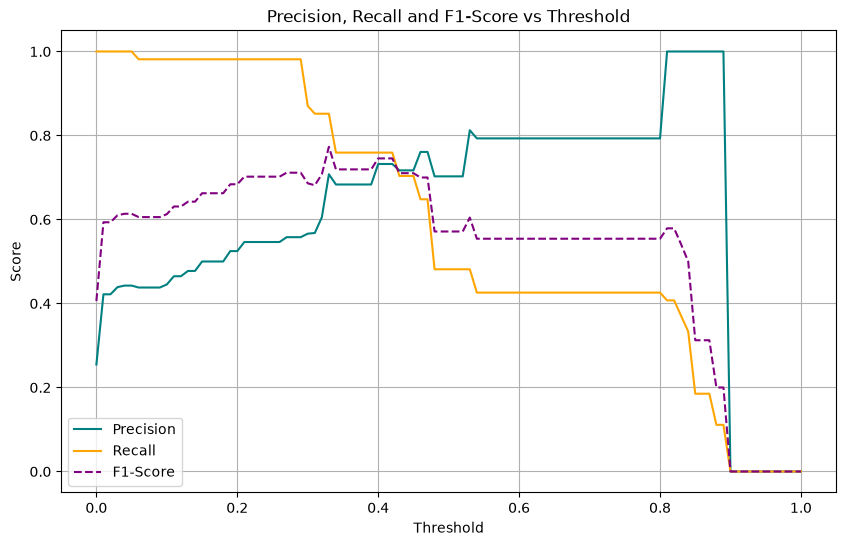

In [207]:
# Precision, Recall, and F1 score

modelLR = train(X_train, y_train, 10)
y_pred = predict_proba(X_val, modelLR)

scores = []
thresholds = np.linspace(0.0, 1.0, 101)

for threshold in thresholds:
    actual_positive = (y_val == 1)
    predicted_positive = (y_pred > threshold)
    precision = precision_score(actual_positive, predicted_positive, zero_division=0)
    recall = recall_score(actual_positive, predicted_positive, zero_division=0)
    f1 = f1_score(actual_positive, predicted_positive, zero_division=0)
    scores.append((threshold, precision, recall, f1))
df_scores = pd.DataFrame(scores, columns=["threshold", "precision", "recall", "f1_score"])

plt.figure(figsize=(10, 6))
plt.plot(df_scores["threshold"], df_scores["precision"], label="Precision", color="teal")
plt.plot(df_scores["threshold"], df_scores["recall"], label="Recall", color="orange")
plt.plot(df_scores["threshold"], df_scores["f1_score"], label="F1-Score", color="purple", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-Score vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [208]:
# Train with optimal C = 10 and threshold = 0.4
selected_threshold = 0.4
selected_C = 10
modelLR = train(X_train, y_train, selected_C)
modelLR
y_pred = predict_proba(X_val, modelLR)
accuracy = calculate_accuracy(y_val, y_pred, selected_threshold)
roc_auc = calculate_roc_auc(y_val, y_pred)
print (f"Accuracy: {accuracy:.3f}, ROC-AUC: {roc_auc:.3f}")

Accuracy: 0.868, ROC-AUC: 0.924


#### Decision Tree Classifier

In [209]:
def train_decision_tree(X_train, y_train, max_depth=None, min_samples_leaf=1):
    model = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf)
    model.fit(X_train, y_train)
    return model

In [210]:
modelDT = train_decision_tree(X_train, y_train)
print(export_text(modelDT, feature_names=dv.get_feature_names_out()))

|--- fat <= 0.50
|   |--- temperature <= 36.50
|   |   |--- temperature <= 35.00
|   |   |   |--- class: 0
|   |   |--- temperature >  35.00
|   |   |   |--- colour <= 250.00
|   |   |   |   |--- class: 0
|   |   |   |--- colour >  250.00
|   |   |   |   |--- class: 1
|   |--- temperature >  36.50
|   |   |--- class: 0
|--- fat >  0.50
|   |--- ph <= 6.55
|   |   |--- ph <= 6.05
|   |   |   |--- class: 0
|   |   |--- ph >  6.05
|   |   |   |--- odor <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- odor >  0.50
|   |   |   |   |--- colour <= 249.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- colour >  249.00
|   |   |   |   |   |--- class: 1
|   |--- ph >  6.55
|   |   |--- ph <= 7.10
|   |   |   |--- turbidity <= 0.50
|   |   |   |   |--- temperature <= 39.00
|   |   |   |   |   |--- colour <= 249.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- colour >  249.50
|   |   |   |   |   |   |--- taste <= 0.50
|   |   |   |   |   |   |   |--- temperature <= 

In [211]:
# Hyperparameter tuning. max_depth
depths = [1, 2, 3, 4, 5, 6, 7]

for depth in depths: 
    modelDT = train_decision_tree(X_train, y_train, max_depth=depth)
    y_pred = predict_proba(X_val, modelDT)
    auc = roc_auc_score(y_val, y_pred)
    print('%4s -> %.3f' % (depth, auc))

   1 -> 0.737
   2 -> 0.844
   3 -> 0.944
   4 -> 0.988
   5 -> 0.998
   6 -> 0.998
   7 -> 0.999


In [212]:
# Hyperparameter tuning. min_samples_leaf
depths = [4, 5, 6, 7]
min_samples_leafs = [1, 5, 10, 15, 20, 500, 100, 200]
scores = []

for depth in depths:
    for s in min_samples_leafs:
        modelDT_i = train_decision_tree(X_train, y_train, max_depth=depth, min_samples_leaf=s)
        y_pred_i = predict_proba(X_val, modelDT_i)
        auc_i = roc_auc_score(y_val, y_pred_i)    
        scores.append((depth, s, auc_i))

columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                     
max_depth             4      5      6      7
min_samples_leaf                            
1                 0.988  0.998  0.998  0.999
5                 0.988  0.998  0.998  0.999
10                0.988  0.998  0.998  0.999
15                0.973  0.994  0.988  0.991
20                0.973  0.994  0.988  0.988
100               0.880  0.880  0.880  0.880
200               0.824  0.824  0.824  0.824
500               0.500  0.500  0.500  0.500

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

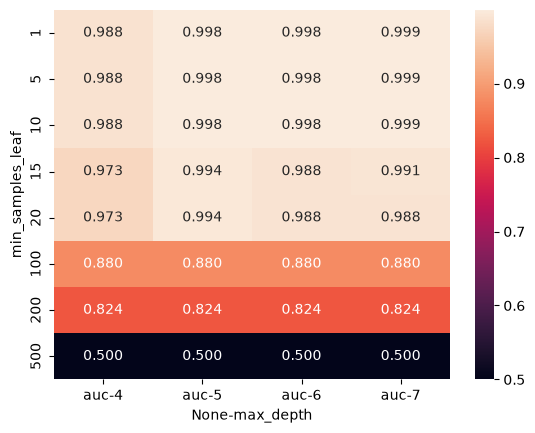

In [213]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

In [214]:
selected_max_depth = 5
selected_min_samples_leaf = 10
print('Although `min_samples_leaf=1` achieves a near-perfect score, `min_samples_leaf=10` is selected alongside `max_depth=5`. This choice drastically reduces the risk of overfitting by preventing the tree from creating hyper-specific branches that memorize individual rows. Since the ROC-AUC remains stable at **0.998**, prioritizing structural robustness guarantees higher generalization capabilities when deployed in production')
print("Selected parameters:")
print(f'max_depth = {selected_max_depth}')
print(f'min_samples_leaf = {selected_min_samples_leaf}')

Although `min_samples_leaf=1` achieves a near-perfect score, `min_samples_leaf=10` is selected alongside `max_depth=5`. This choice drastically reduces the risk of overfitting by preventing the tree from creating hyper-specific branches that memorize individual rows. Since the ROC-AUC remains stable at **0.998**, prioritizing structural robustness guarantees higher generalization capabilities when deployed in production
Selected parameters:
max_depth = 5
min_samples_leaf = 10


In [215]:
modelDT = train_decision_tree(X_train, y_train, max_depth=selected_max_depth, min_samples_leaf=selected_min_samples_leaf)
y_pred = predict(X_val, modelDT)
accuracy = calculate_accuracy(y_val, y_pred, selected_threshold)
roc_auc = roc_auc_score(y_val, y_pred)
print (f"Accuracy: {accuracy:.3f}, ROC-AUC: {roc_auc:.3f}")

Accuracy: 0.986, ROC-AUC: 0.972


In [216]:
print(export_text(modelDT, feature_names=dv.get_feature_names_out()))

|--- fat <= 0.50
|   |--- temperature <= 36.50
|   |   |--- odor <= 0.50
|   |   |   |--- class: 0
|   |   |--- odor >  0.50
|   |   |   |--- class: 0
|   |--- temperature >  36.50
|   |   |--- class: 0
|--- fat >  0.50
|   |--- ph <= 6.55
|   |   |--- ph <= 6.05
|   |   |   |--- class: 0
|   |   |--- ph >  6.05
|   |   |   |--- odor <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- odor >  0.50
|   |   |   |   |--- class: 1
|   |--- ph >  6.55
|   |   |--- ph <= 7.10
|   |   |   |--- turbidity <= 0.50
|   |   |   |   |--- temperature <= 39.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- temperature >  39.00
|   |   |   |   |   |--- class: 0
|   |   |   |--- turbidity >  0.50
|   |   |   |   |--- class: 1
|   |   |--- ph >  7.10
|   |   |   |--- class: 0



#### Random Forests Classifier

In [217]:
def train_random_forest(X_train, y_train, n_estimators=100, max_depth=None, min_samples_leaf=1, random_state=1):
    modelRF = RandomForestClassifier(
        n_estimators=n_estimators, 
        max_depth=max_depth, 
        min_samples_leaf=min_samples_leaf, 
        random_state=random_state,
        n_jobs=-1
    )
    modelRF.fit(X_train, y_train)
    return modelRF

In [218]:
# Hyperparameter tuning

# max_depths - n_estimators
max_depths = [1, 2, 3]
n_estimators = range(10, 201, 10)
scores = []

for max_depth in max_depths:
    for n_estimator in n_estimators:
        model_i = train_random_forest(X_train, y_train, n_estimator, max_depth)
        y_pred_i = predict_proba(X_val, model_i)
        auc_i = roc_auc_score(y_val, y_pred_i)
        scores.append((max_depth, n_estimator, auc_i))
columns = ['max_depth', 'n_estimator', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)


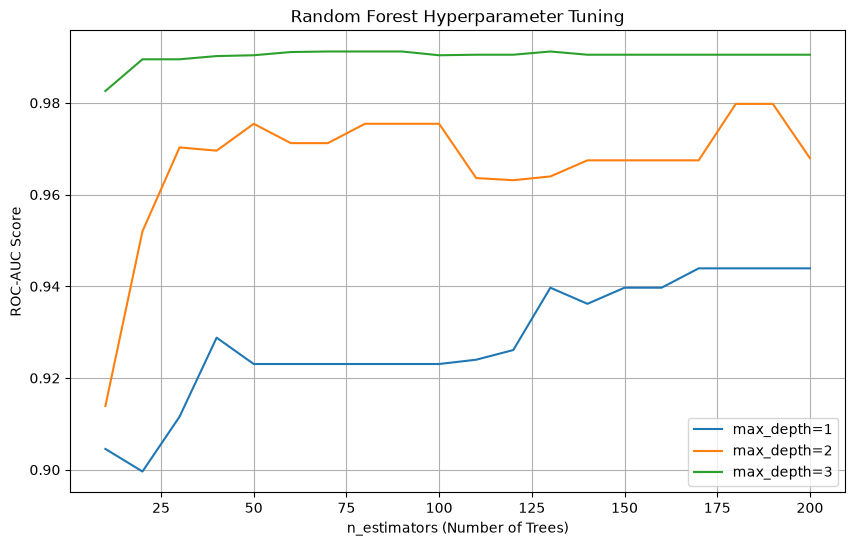

In [219]:
plt.figure(figsize=(10, 6))
for d_v in max_depths:
    df_subset = df_scores[df_scores.max_depth == d_v]
    plt.plot(df_subset['n_estimator'], df_subset['auc'], label=f'max_depth={d_v}')

plt.xlabel("n_estimators (Number of Trees)")
plt.ylabel("ROC-AUC Score")
plt.title("Random Forest Hyperparameter Tuning")
plt.legend()
plt.grid(True)
plt.show()

In [220]:
max_depth = 3
n_estimators = 50
print(f"Selection n_estimators={n_estimators}, max_depth={max_depth}")

Selection n_estimators=50, max_depth=3


In [221]:
# min_samples_leaf - n_estimators
min_samples_leafs = [1, 3, 5, 10 , 50]
n_estimators = range(10, 201, 10)
scores = []

for min_samples_leaf in min_samples_leafs:
    for n_estimator in n_estimators:
        model_i = train_random_forest(X_train, y_train, n_estimator, max_depth, min_samples_leaf)
        y_pred_i = predict_proba(X_val, model_i)
        auc_i = roc_auc_score(y_val, y_pred_i)
        scores.append((min_samples_leaf, n_estimator, auc_i))
columns = ['min_samples_leaf', 'n_estimator', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)


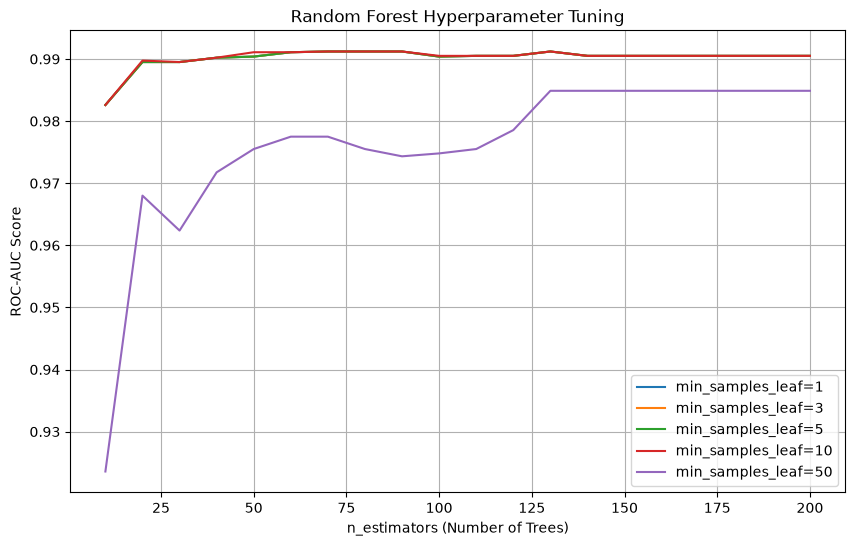

In [222]:
plt.figure(figsize=(10, 6))
for d_v in min_samples_leafs:
    df_subset = df_scores[df_scores.min_samples_leaf == d_v]
    plt.plot(df_subset['n_estimator'], df_subset['auc'], label=f'min_samples_leaf={d_v}')

plt.xlabel("n_estimators (Number of Trees)")
plt.ylabel("ROC-AUC Score")
plt.title("Random Forest Hyperparameter Tuning")
plt.legend()
plt.grid(True)
plt.show()

In [223]:
max_depth = 3
n_estimators = 50
min_sample_leaf = 10
print(f"Selection n_estimators={n_estimators}, max_depth={max_depth}, min_sample_depth={min_sample_leaf}")

Selection n_estimators=50, max_depth=3, min_sample_depth=10


In [224]:
model_RF = train_random_forest(X_train, y_train, n_estimator, max_depth, min_sample_leaf)
y_pred = predict_proba(X_val, model_RF)
accuracy = calculate_accuracy(y_val, y_pred, selected_threshold)
roc_auc = roc_auc_score(y_val, y_pred)
print (f"Accuracy: {accuracy:.3f}, ROC-AUC: {roc_auc:.3f}")


Accuracy: 0.972, ROC-AUC: 0.991


#### Gradient Boosting Classifier

In [225]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
watchlist = [(dtrain, 'train'), (dval, 'val')]


In [226]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'nthread': 8,
    'eval_metric': 'auc',
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100, verbose_eval=5, evals=watchlist)
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

In [227]:
s = output.stdout

In [228]:
print(s[:200])

[0]	train-auc:0.92598	val-auc:0.94398
[5]	train-auc:0.97125	val-auc:0.96806
[10]	train-auc:0.98384	val-auc:0.98400
[15]	train-auc:0.98893	val-auc:0.98928
[20]	train-auc:0.99536	val-auc:0.99379
[25]	tr


In [229]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

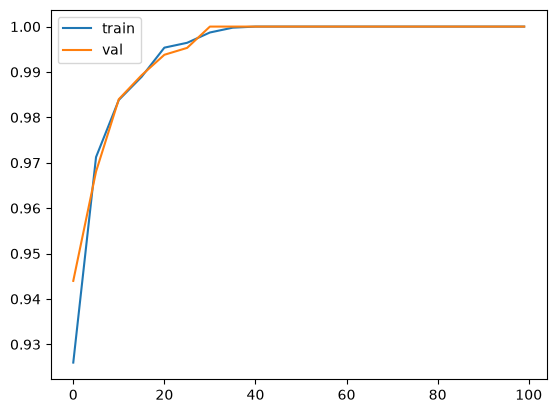

In [230]:
df_score = parse_xgb_output(output)
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

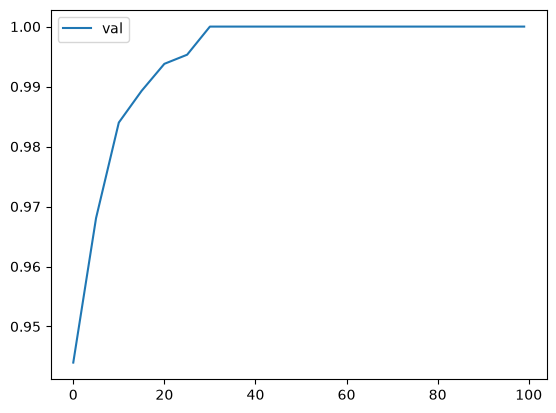

In [231]:
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

In [256]:
scores = {}

In [264]:
%%capture output

xgb_params = {
    'eta': 0.03, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

modelXGB = xgb.train(xgb_params, dtrain, num_boost_round=75, verbose_eval=5, evals=watchlist)
y_pred = modelXGB.predict(dval)
roc_auc_score(y_val, y_pred)

In [265]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.03'

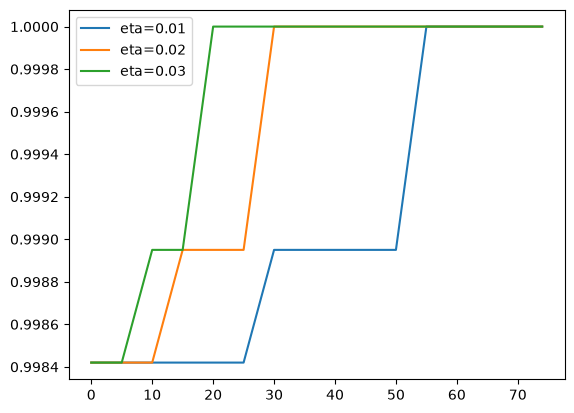

In [266]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)
plt.legend()

In [236]:
eta_selected = 0.03
print(f"eta: {eta_selected}")

eta: 0.03


In [267]:
# max_depth

scores = {}

In [274]:
%%capture output

xgb_params = {
    'eta': 0.03, 
    'max_depth': 3,
    'min_child_weight': 1,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

modelXGB = xgb.train(xgb_params, dtrain, num_boost_round=75, verbose_eval=5, evals=watchlist)
y_pred = modelXGB.predict(dval)
roc_auc_score(y_val, y_pred)

In [275]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=3'

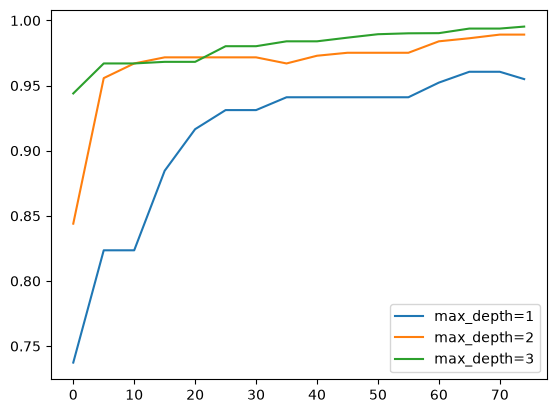

In [276]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)
plt.legend()

In [241]:
max_depth_selected = 3
print(f"max_depth: {max_depth_selected}")

max_depth: 3


In [277]:
# min_child_weight

scores = {}

In [284]:
%%capture output

xgb_params = {
    'eta': 0.01, 
    'max_depth': 3,
    'min_child_weight': 100,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

modelXGB = xgb.train(xgb_params, dtrain, num_boost_round=75, verbose_eval=5, evals=watchlist)
y_pred = modelXGB.predict(dval)
roc_auc_score(y_val, y_pred)

In [285]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=100'

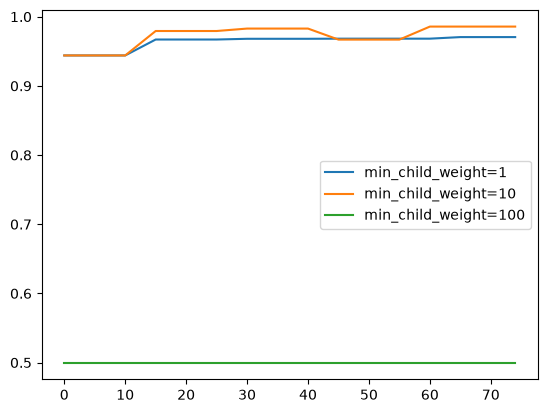

In [286]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)
plt.legend()

In [287]:
min_child_weight_selected = 1
print(f"min_child_weight: {min_child_weight_selected}")

min_child_weight: 1


In [288]:
xgb_params = {
    'eta': eta_selected,
    'max_depth': max_depth_selected,
    'min_child_weight': min_child_weight_selected,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

modelXGB_final = xgb.train(xgb_params, dtrain, num_boost_round=75, verbose_eval=5, evals=watchlist)
y_pred = modelXGB_final.predict(dval)
accuracy = calculate_accuracy(y_val, y_pred, selected_threshold)
roc_auc = roc_auc_score(y_val, y_pred)
print (f"Accuracy: {accuracy:.3f}, ROC-AUC: {roc_auc:.3f}")

[0]	train-auc:0.92598	val-auc:0.94398
[5]	train-auc:0.96656	val-auc:0.96701
[10]	train-auc:0.96713	val-auc:0.96701
[15]	train-auc:0.97214	val-auc:0.96824
[20]	train-auc:0.97221	val-auc:0.96824
[25]	train-auc:0.98110	val-auc:0.98025
[30]	train-auc:0.98103	val-auc:0.98025
[35]	train-auc:0.98384	val-auc:0.98400
[40]	train-auc:0.98434	val-auc:0.98400
[45]	train-auc:0.98726	val-auc:0.98681
[50]	train-auc:0.98956	val-auc:0.98945
[55]	train-auc:0.98997	val-auc:0.99015
[60]	train-auc:0.99004	val-auc:0.99027
[65]	train-auc:0.99521	val-auc:0.99379
[70]	train-auc:0.99536	val-auc:0.99379
[74]	train-auc:0.99643	val-auc:0.99531
Accuracy: 0.972, ROC-AUC: 0.995


#### Model Selection

In [289]:
df_full_train = df_full_train.reset_index(drop=True)
if 'grade' in df_full_train.columns:
    y_full_train = df_full_train['grade'].values
    del df_full_train['grade']
dicts_full_train = df_full_train.to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)
dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

features = list(dv.get_feature_names_out())
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
dtest = xgb.DMatrix(X_test, feature_names=features)

xgb_params = {
    'eta': eta_selected,
    'max_depth': max_depth_selected,
    'min_child_weight': min_child_weight_selected,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

modelXGB_final = xgb.train(xgb_params, dfulltrain, num_boost_round=75)
y_pred = modelXGB_final.predict(dtest)
roc_auc = calculate_roc_auc(y_test, y_pred)
print(f'XGB AUC: {roc_auc}')

XGB AUC: 0.998


#### Save Model

In [290]:
model_file_path = '../models/modelXB.bin'
with open(model_file_path, 'wb') as f_out:
    pickle.dump((dv, modelXGB_final), f_out)


#### Test Model

In [304]:
milk_sample = df_test.iloc[2]
print('sample')
print('-----')
print(milk_sample)
print('-----')
print(f'es_premium_test = {y_test[2]}')
print('-----')

with open(model_file_path, 'rb') as f_in:
    dv, model_saved = pickle.load(f_in)

X = dv.transform([milk_sample])
features = list(dv.get_feature_names_out())
dX = xgb.DMatrix(X, feature_names=features)
y_pred = model_saved.predict(dX)

print(f'prediction = {y_pred[0]}')
print(f'Is High Grade (threshold=0.4) = {y_pred[0] >= selected_threshold}')

sample
-----
ph               6.8
temperature     45.0
taste            0.0
odor             1.0
fat              1.0
turbidity        1.0
colour         255.0
Name: 2, dtype: float64
-----
es_premium_test = 1
-----
prediction = 0.8082966804504395
Is High Grade (threshold=0.4) = True
